# 03 — Experiments B, C, E & F: Controlled Shift Replay & Lead-Time ($\Delta t$) Comparison
Replays `test_stream.parquet` window by window (2,000 flows/window) anchored around the chronological attack wave, injects controlled shifts (`covariate_benign` vs. `concept_proxy`), unlocks labels to detect $t_{\text{fail}}$, and compares `M3` vs. `M4` lead times ($\Delta t = t_{\text{fail}} - t_{\text{alarm}}$).

In [1]:
import sys
import json
from pathlib import Path

ML_SERVICE_ROOT = Path.cwd().resolve()
if ML_SERVICE_ROOT.name == "notebooks":
    ML_SERVICE_ROOT = ML_SERVICE_ROOT.parent
if str(ML_SERVICE_ROOT) not in sys.path:
    sys.path.insert(0, str(ML_SERVICE_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
from src.config import settings
from src.logger import setup_logging

setup_logging()
print("Connected to ML Service Root:", ML_SERVICE_ROOT)
from src.service.model_engine import IDSEngine
from src.service.monitors import DriftMonitorSuite
from src.service.shift_simulator import run_controlled_experiment

with open(settings.SPLITS_DIR / 'split_metadata.json', encoding='utf-8') as f:
    feature_cols = json.load(f)['feature_cols']
test_df = pd.read_parquet(settings.SPLITS_DIR / 'test_stream.parquet')
engine = IDSEngine.load(settings.ARTIFACTS_DIR / 'xgb_ids.joblib')
monitor = DriftMonitorSuite.load(settings.ARTIFACTS_DIR / 'reference_profile.joblib', settings.ARTIFACTS_DIR / 'thresholds.json', min_bucket_samples=settings.MIN_BUCKET_SAMPLES)

Connected to ML Service Root: C:\Users\Dell\Desktop\ea-idrs\ml-service


In [2]:
from src.service.shifts import build_shift_context

# Grid v5 setup (see README and docs/experiment-log.md): realistic attack_mimicry shift on a
# 20-window geometric ramp; degradation = recall drop of 0.15 from the clean-validation baseline.
TARGET = "DDoS"
RECALL_DROP = 0.15
with open(settings.ARTIFACTS_DIR / "baseline_metrics.json", encoding="utf-8") as f:
    baseline_recall = json.load(f)[TARGET]["recall"]
val_df = pd.read_parquet(settings.SPLITS_DIR / "val_clean.parquet", columns=feature_cols + ["target"])
shift_context = build_shift_context(val_df, feature_cols, [TARGET], seed=settings.RANDOM_SEED)

exp_result = run_controlled_experiment(
    test_df=test_df,
    feature_cols=feature_cols,
    engine=engine,
    monitor=monitor,
    target_attack=TARGET,
    shift_type="attack_mimicry",
    max_windows=40,
    recall_cutoff=baseline_recall - RECALL_DROP + 1e-12,
    shift_context=shift_context,
    ramp="geometric",
    ramp_windows=20,
)

shift_start = exp_result["shift_start_window"]
t_fail = exp_result["t_fail"]
recall_cutoff = exp_result["recall_cutoff"]
replay_df = pd.DataFrame(exp_result["windows"])

print(f"Shift starts at window {shift_start} | recall degraded (< {recall_cutoff:.4f}) at window {t_fail}")
display(pd.DataFrame(exp_result["monitor_comparison"])[["monitor", "t_alarm", "t_fail", "lead_time_delta_t", "missed_degradation"]])

2026-11-25 17:11:04 | INFO     | src.service.shift_simulator:154 | Running experiment | attack=DDoS | shift=attack_mimicry | windows=443..486 | shift_start=459


Shift starts at window 459 | recall degraded (< 0.8497) at window 472


,monitor,t_alarm,t_fail,lead_time_delta_t,missed_degradation
0,M1,NaN,472,NaN,True
1,M2,459.0,472,13.0,False
2,M3,459.0,472,13.0,False
3,M4,459.0,472,13.0,False


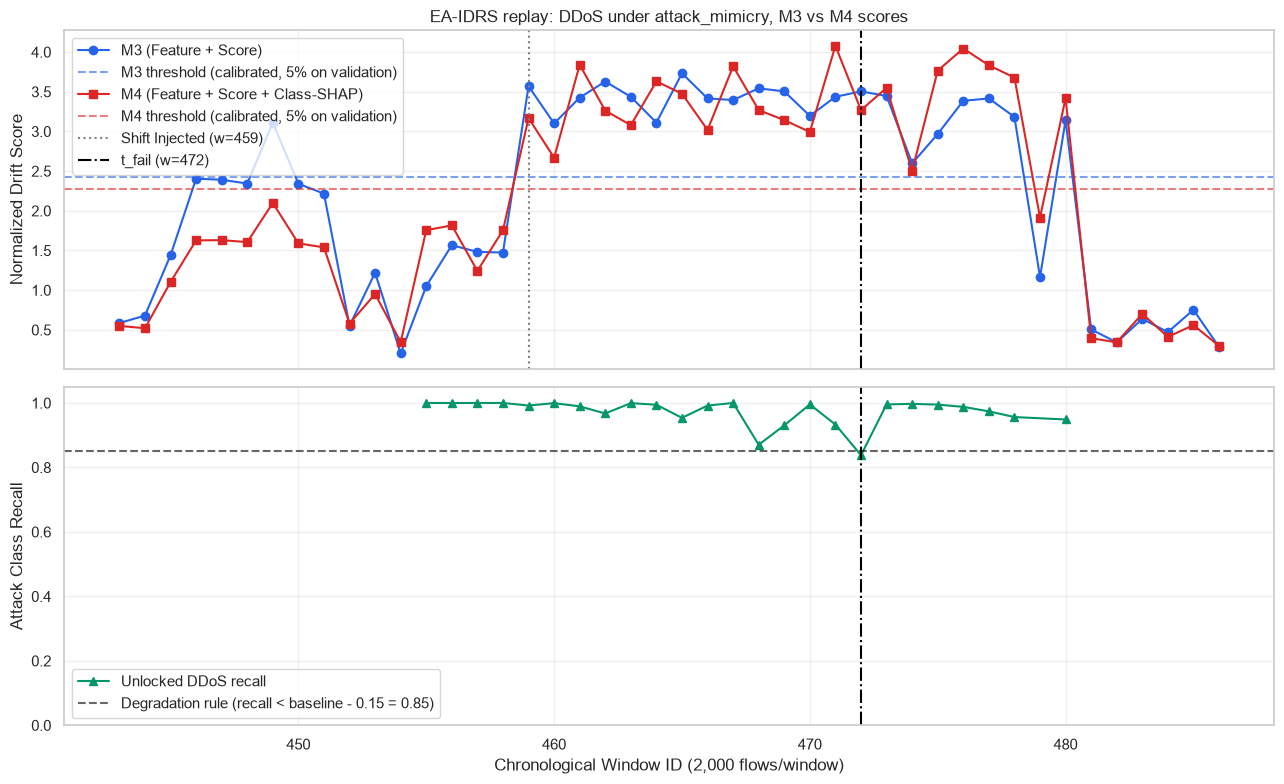

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

ax1.plot(replay_df["window_id"], replay_df["m3_score"], label="M3 (Feature + Score)", marker="o", color="#2563eb")
ax1.axhline(monitor.thresholds.m3_threshold, linestyle="--", color="#2563eb", alpha=0.6, label="M3 threshold (calibrated, 5% on validation)")
ax1.plot(replay_df["window_id"], replay_df["m4_score"], label="M4 (Feature + Score + Class-SHAP)", marker="s", color="#dc2626")
ax1.axhline(monitor.thresholds.m4_threshold, linestyle="--", color="#dc2626", alpha=0.6, label="M4 threshold (calibrated, 5% on validation)")
ax1.axvline(shift_start, color="gray", linestyle=":", label=f"Shift Injected (w={shift_start})")
if t_fail is not None:
    ax1.axvline(t_fail, color="black", linestyle="-.", label=f"t_fail (w={t_fail})")
ax1.set_ylabel("Normalized Drift Score")
ax1.set_title(f"EA-IDRS replay: {TARGET} under attack_mimicry, M3 vs M4 scores")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

valid_rec = replay_df.dropna(subset=["target_recall"])
ax2.plot(valid_rec["window_id"], valid_rec["target_recall"], label=f"Unlocked {TARGET} recall", marker="^", color="#059669")
ax2.axhline(recall_cutoff, linestyle="--", color="black", alpha=0.6, label=f"Degradation rule (recall < baseline - {RECALL_DROP} = {recall_cutoff:.2f})")
if t_fail is not None:
    ax2.axvline(t_fail, color="black", linestyle="-.")
ax2.set_ylabel("Attack Class Recall")
ax2.set_xlabel("Chronological Window ID (2,000 flows/window)")
ax2.set_ylim(0, 1.05)
ax2.legend(loc="lower left")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

This notebook shows one run. The full pre-registered evaluation (21 runs, lead times at matched false-alarm rates, alarms attributed against a control run) is `python -m src.service.run_grid`, and `python -m src.service.report` turns a grid run into the results table and figures. Results and their history: `docs/experiment-log.md`.